In [4]:
# Importing libraries
import pandas as pd
import numpy as np

# Load the dataset
# Replace 'malicious_phish.csv' with your actual file path
df = pd.read_csv('malicious_phish.csv')

# Display the first few rows of the dataset
print("Sample Rows:")
print(df.head())

# Display basic information about the dataset
print("\nDataset Info:")
print(df.info())

# Check for null values
print("\nNull Values:")
print(df.isnull().sum())

# Distribution of the target labels
print("\nLabel Distribution:")
print(df['type'].value_counts())

# Removing duplicates if any
df = df.drop_duplicates()
print(f"\nDataset after removing duplicates: {df.shape}")

# Add a column for URL length
df['url_length'] = df['url'].apply(len)

# Add a column for the count of special characters
special_characters = ['@', '?', '%', '.', '=', '-', '/']
for char in special_characters:
    df[f'count_{char}'] = df['url'].apply(lambda x: x.count(char))

# Add a column for the presence of certain keywords
keywords = ['secure', 'login', 'free', 'verify']
for keyword in keywords:
    df[f'has_{keyword}'] = df['url'].apply(lambda x: int(keyword in x.lower()))

# Display the updated dataset structure
print("\nUpdated Dataset Sample:")
print(df.head())

# Save the processed dataset (optional)
df.to_csv('processed_malicious_phish.csv', index=False)
print("\nProcessed dataset saved as 'processed_malicious_phish.csv'.")


Sample Rows:
                                                 url        type
0                                   br-icloud.com.br    phishing
1                mp3raid.com/music/krizz_kaliko.html      benign
2                    bopsecrets.org/rexroth/cr/1.htm      benign
3  http://www.garage-pirenne.be/index.php?option=...  defacement
4  http://adventure-nicaragua.net/index.php?optio...  defacement

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 651191 entries, 0 to 651190
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   url     651191 non-null  object
 1   type    651191 non-null  object
dtypes: object(2)
memory usage: 9.9+ MB
None

Null Values:
url     0
type    0
dtype: int64

Label Distribution:
type
benign        428103
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64

Dataset after removing duplicates: (641125, 2)

Updated Dataset Sample:
                       

In [6]:
# Import necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Load the processed dataset
df = pd.read_csv('processed_malicious_phish.csv')

# Preview the dataset
print("Dataset Preview:")
print(df.head())

# Map the target 'type' column to numeric labels
target_mapping = {'benign': 0, 'phishing': 1, 'defacement': 2}
df['type_encoded'] = df['type'].map(target_mapping)

# Verify target mapping
print("\nTarget Mapping Verification:")
print(df['type_encoded'].value_counts())

# Extract features and target
X = df.drop(columns=['type', 'type_encoded', 'url'])  # Use only numeric columns as features
y = df['type_encoded']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("\nData Split:")
print(f"Training Features: {X_train.shape}")
print(f"Testing Features: {X_test.shape}")

# Train Logistic Regression model
print("\nTraining Logistic Regression Model...")
model = LogisticRegression(max_iter=1000, multi_class='ovr', solver='lbfgs')
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"\nModel Accuracy: {accuracy:.2f}\n")

# Detailed classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=target_mapping.keys()))

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=target_mapping.keys(), yticklabels=target_mapping.keys())
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


Dataset Preview:
                                                 url        type  url_length  \
0                                   br-icloud.com.br    phishing          16   
1                mp3raid.com/music/krizz_kaliko.html      benign          35   
2                    bopsecrets.org/rexroth/cr/1.htm      benign          31   
3  http://www.garage-pirenne.be/index.php?option=...  defacement          88   
4  http://adventure-nicaragua.net/index.php?optio...  defacement         235   

   count_@  count_?  count_%  count_.  count_=  count_-  count_/  has_secure  \
0        0        0        0        2        0        1        0           0   
1        0        0        0        2        0        0        2           0   
2        0        0        0        2        0        0        3           0   
3        0        1        0        3        4        1        3           0   
4        0        1        0        2        3        1        3           0   

   has_login  has_fre

ValueError: Input y contains NaN.

In [8]:
# Check for missing values in the target column
print("Checking for NaN values in the target (y):")
print(y.isnull().sum())

# If NaN values exist, inspect the rows
if y.isnull().sum() > 0:
    print("\nRows with NaN in target (type_encoded):")
    print(df[df['type_encoded'].isnull()])


Checking for NaN values in the target (y):
23645

Rows with NaN in target (type_encoded):
                                                      url     type  \
38      http://www.824555.com/app/member/SportOption.p...  malware   
115     http://9779.info/%E5%84%BF%E7%AB%A5%E7%AB%8B%E...  malware   
156     http://9779.info/%E6%A0%91%E5%8F%B6%E7%B2%98%E...  malware   
212     http://9779.info/%E5%8F%A4%E4%BB%A3%E4%BA%8C%E...  malware   
240     http://chinacxyy.com/piccodejs-000.asp?lm2=191...  malware   
...                                                   ...      ...   
545117                 http://211.137.225.95:47475/Mozi.m  malware   
545118                 http://115.55.246.246:44661/Mozi.m  malware   
545119                http://219.155.142.211:55621/Mozi.m  malware   
545120                   http://42.238.164.8:48848/Mozi.m  malware   
545121                   http://172.36.45.82:41684/Mozi.m  malware   

        url_length  count_@  count_?  count_%  count_.  count_=  coun

In [10]:
# Drop rows with NaN values in the target column
df_cleaned = df.dropna(subset=['type_encoded'])

# Update X and y after removing rows
X = df_cleaned.drop(columns=['type', 'type_encoded', 'url'])
y = df_cleaned['type_encoded']


In [14]:
# Fill NaN values with a default label (e.g., benign = 0)
df['type_encoded'] = df['type_encoded'].fillna(0)

# Update X and y after filling NaN values
X = df.drop(columns=['type', 'type_encoded', 'url'])
y = df['type_encoded']


In [16]:
# Verify no NaN values remain
print("NaN values in target column after cleaning:")
print(y.isnull().sum())


NaN values in target column after cleaning:
0


In [18]:
# Check again for missing values
print("\nAfter cleaning, NaN values in target (y):")
print(y.isnull().sum())



After cleaning, NaN values in target (y):
0


In [20]:
# Re-split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Logistic Regression model
model = LogisticRegression(max_iter=1000, multi_class='ovr', solver='lbfgs')
model.fit(X_train, y_train)

print("Model training complete!")


Model training complete!


In [22]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Make predictions on the test set
y_pred = model.predict(X_test_scaled)  # Use scaled test features if scaling was applied

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"\nModel Accuracy: {accuracy:.2f}\n")

# Generate and print classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Create and display confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', 
            xticklabels=target_mapping.keys(), yticklabels=target_mapping.keys())
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

NameError: name 'X_test_scaled' is not defined

In [24]:
y_pred = model.predict(X_test)  # Use unscaled test data if scaling wasn't applied


In [26]:
from sklearn.preprocessing import StandardScaler

# Ensure scaling of both training and testing features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train model with scaled features
model.fit(X_train_scaled, y_train)

# Make predictions with scaled test features
y_pred = model.predict(X_test_scaled)


In [28]:
from sklearn.preprocessing import StandardScaler

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Logistic Regression with scaled features
print("\nTraining Logistic Regression with scaled features...")
model = LogisticRegression(max_iter=1000, multi_class='ovr', solver='lbfgs')
model.fit(X_train_scaled, y_train)

# Make predictions on the scaled test data
y_pred = model.predict(X_test_scaled)

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"\nModel Accuracy: {accuracy:.2f}\n")



Training Logistic Regression with scaled features...

Model Accuracy: 0.75



Classification Report:
              precision    recall  f1-score   support

         0.0       0.75      0.97      0.85     90211
         1.0       0.49      0.02      0.04     18872
         2.0       0.74      0.45      0.56     19142

    accuracy                           0.75    128225
   macro avg       0.66      0.48      0.48    128225
weighted avg       0.71      0.75      0.69    128225



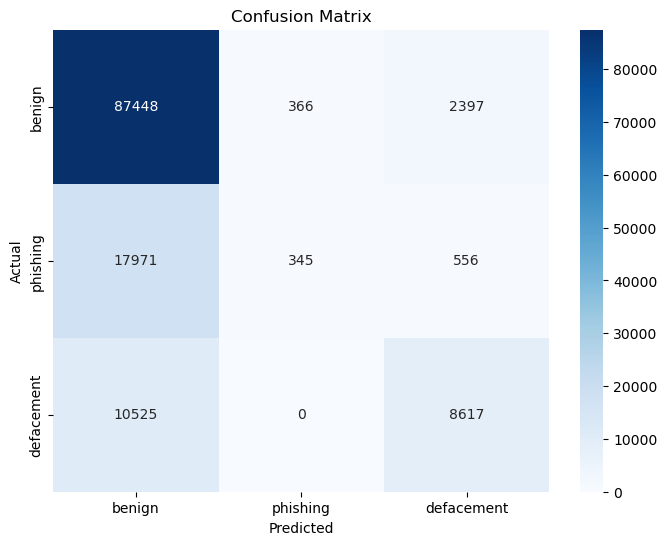

In [30]:
# Generate and print classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', 
            xticklabels=target_mapping.keys(), yticklabels=target_mapping.keys())
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [32]:
from sklearn.model_selection import GridSearchCV

# Define hyperparameter grid
param_grid = {
    'C': [0.1, 1, 10],  # Regularization strength
    'solver': ['lbfgs', 'saga'],  # Solver options
    'max_iter': [1000, 2000]
}

# GridSearch
grid_search = GridSearchCV(LogisticRegression(multi_class='ovr'), param_grid, cv=3, scoring='accuracy')
grid_search.fit(X_train_scaled, y_train)
print("Best Parameters:", grid_search.best_params_)

# Use the best model
best_model = grid_search.best_estimator_


Best Parameters: {'C': 1, 'max_iter': 2000, 'solver': 'saga'}


In [33]:
from sklearn.ensemble import RandomForestClassifier

# Train Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

# Evaluate Random Forest
rf_predictions = rf_model.predict(X_test_scaled)
rf_accuracy = accuracy_score(y_test, rf_predictions)
print(f"Random Forest Accuracy: {rf_accuracy:.2f}")


Random Forest Accuracy: 0.86
